# 🏠 Pakistan Real Estate Market Analysis
## Zameen.com — Exploratory Data Analysis Project

**Objective:** Analyze 190,000+ property listings from Zameen.com to uncover market trends, evaluate regional pricing disparities, and provide data-driven recommendations for investors, agencies, and home buyers.

**Dataset:** Property listings scraped from zameen.com (Pakistan's largest real estate portal)  
**Tools:** Python · Pandas · NumPy · Matplotlib · Seaborn

---

## Phase 1: Import Libraries and Load Data

We begin by importing the Python libraries we'll use throughout this analysis. Each library has a specific role:

| Library | Purpose |
|---------|---------|
| `pandas` | Data manipulation — reading CSVs, filtering, grouping, aggregating |
| `numpy` | Numerical operations — mean, log transforms, array math |
| `matplotlib` | Core plotting engine — histograms, scatter plots, bar charts |
| `seaborn` | Statistical visualizations built on matplotlib — heatmaps, boxplots |
| `warnings` | Suppress non-critical warning messages to keep output clean |

In [ ]:
# ──────────────────────────────────────────────
# 1.1  Import all required libraries
# ──────────────────────────────────────────────

import pandas as pd               # Data manipulation & analysis
import numpy as np                # Numerical computing
import matplotlib.pyplot as plt   # Core plotting library
import seaborn as sns             # Statistical data visualization
import warnings                   # To suppress non-critical warnings

# Suppress FutureWarnings and other noise so our output stays clean
warnings.filterwarnings('ignore')

# Set global style for all plots — 'whitegrid' adds light gridlines
# which make it easier to read values off charts
sns.set_style('whitegrid')

# Set a default figure size so all plots are large enough to read
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


### 1.2  Load the Dataset

The CSV file uses **semicolons (`;`)** as delimiters instead of the usual commas. This is common in datasets from European or South Asian portals. If we don't specify `sep=';'`, pandas would treat the entire row as a single column.

> **Google Colab tip:** Upload `Property.csv` to your Colab session first, or mount Google Drive and adjust the path accordingly.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd # Added to resolve NameError
# ──────────────────────────────────────────────
# 1.2  Load the CSV file
# ──────────────────────────────────────────────

# IMPORTANT: The file uses semicolons as separators, NOT commas.
# If you forget sep=';', the entire row will load into ONE column.

# Assuming 'Property.csv' is in the root of your Google Drive
df = pd.read_csv('ADD THE GDRIVE PATH HERE', sep=';')

# Quick sanity check — did it load correctly?
print(f"Dataset loaded successfully!")
print(f"Shape: {df.shape[0]:,} rows  ×  {df.shape[1]} columns")

Dataset loaded successfully!
Shape: 191,393 rows  ×  17 columns


### 1.3  Data Overview & Quality Check

Before doing any analysis, we need to **understand what we're working with**. Think of this as "opening the box and inspecting what's inside." We check:
- What the first/last rows look like (did it load properly?)
- How many rows and columns we have
- What data types each column has (numbers? text? dates?)
- How many values are missing

In [ ]:
# ──────────────────────────────────────────────
# 1.3a  Display the first 5 rows
# ──────────────────────────────────────────────
# .head() shows the TOP rows — helps us see column names,
# data formats, and whether the import went smoothly.

df.head()

,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent
0,347795,8,https://www.zameen.com/Property/lahore_model_t...,House,220000000,Model Town,Lahore,Punjab,31.483869,74.325686,0,6 Kanal,For Sale,0,07-17-2019,Real Biz International,Usama Khan
1,482892,48,https://www.zameen.com/Property/lahore_multan_...,House,40000000,Multan Road,Lahore,Punjab,31.431593,74.179980,5,1 Kanal,For Sale,5,10-06-2018,Khan Estate,mohsinkhan and B
2,555962,75,https://www.zameen.com/Property/eden_eden_aven...,House,9500000,Eden,Lahore,Punjab,31.499348,74.416959,0,9 Marla,For Sale,3,07-03-2019,Shahum Estate 2,"Babar Hameed, Raja Omar"
3,562843,3821,https://www.zameen.com/Property/gulberg_2_gulb...,House,125000000,Gulberg,Lahore,Punjab,31.522069,74.355512,7,1 Kanal,For Sale,8,04-04-2019,NaN,NaN
4,686990,3522,https://www.zameen.com/Property/allama_iqbal_t...,House,21000000,Allama Iqbal Town,Lahore,Punjab,31.506483,74.286017,5,11 Marla,For Sale,6,04-04-2019,NaN,NaN


In [ ]:
# ──────────────────────────────────────────────
# 1.3b  Display the last 5 rows
# ──────────────────────────────────────────────
# .tail() shows the BOTTOM rows — ensures the file
# loaded completely and wasn't truncated.

df.tail()

,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent
191388,17468383,174,https://www.zameen.com/Property/islamabad_i_8_...,Upper Portion,70000,I-8,Islamabad,Islamabad Capital,33.668497,73.074160,0,12.4 Marla,For Rent,3,07-24-2019,Property World,Zafran
191389,17468384,174,https://www.zameen.com/Property/islamabad_i_8_...,Upper Portion,40000,I-8,Islamabad,Islamabad Capital,33.668497,73.074160,0,12.4 Marla,For Rent,2,07-24-2019,Property World,Zafran
191390,17468482,167,https://www.zameen.com/Property/islamabad_g_10...,House,160000,G-10,Islamabad,Islamabad Capital,33.676104,73.013842,6,1 Kanal,For Rent,6,07-24-2019,Azaan Associates,Usman Rehman
191391,17468586,339,https://www.zameen.com/Property/dha_defence_dh...,Flat,25000,DHA Defence,Islamabad,Islamabad Capital,33.527944,73.161392,2,2.7 Marla,For Rent,2,07-24-2019,New National Properties,TALHA MIAN AHMAD
191392,17468660,3421,https://www.zameen.com/Property/i_10_i_10_2_i_...,Upper Portion,26000,I-10,Islamabad,Islamabad Capital,33.649779,73.029385,1,0 Marla,For Rent,3,07-24-2019,Select Homes,"Qaiser Shahzad, Chaudhary Waseem"


In [ ]:
# ──────────────────────────────────────────────
# 1.3c  Dimensions of the dataset
# ──────────────────────────────────────────────
# .shape returns a tuple: (number_of_rows, number_of_columns)

rows, cols = df.shape
print(f"Rows:    {rows:,}")
print(f"Columns: {cols}")

Rows:    191,393
Columns: 17


In [ ]:
# ──────────────────────────────────────────────
# 1.3d  List all column names
# ──────────────────────────────────────────────
# This gives us the full list of features (variables) in the dataset.

print(f"Total features: {len(df.columns)}\n")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2d}. {col}")

Total features: 17

   1. property_id
   2. location_id
   3. page_url
   4. property_type
   5. price
   6. location
   7. city
   8. province_name
   9. latitude
  10. longitude
  11. baths
  12. area
  13. purpose
  14. bedrooms
  15. date_added
  16. agency
  17. agent


In [ ]:
# ──────────────────────────────────────────────
# 1.3e  Data types and non-null counts
# ──────────────────────────────────────────────
# .info() is one of the MOST useful commands in pandas.
# It shows:
#   - Each column's data type (int64, float64, object/string)
#   - How many NON-null values each column has
#   - Memory usage
#
# If "Non-Null Count" is less than the total rows, that column has missing data.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 191393 entries, 0 to 191392
Data columns (total 17 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   property_id    191393 non-null  int64  
 1   location_id    191393 non-null  int64  
 2   page_url       191393 non-null  object 
 3   property_type  191393 non-null  object 
 4   price          191393 non-null  int64  
 5   location       191393 non-null  object 
 6   city           191393 non-null  object 
 7   province_name  191393 non-null  object 
 8   latitude       191393 non-null  float64
 9   longitude      191393 non-null  float64
 10  baths          191393 non-null  int64  
 11  area           191393 non-null  object 
 12  purpose        191393 non-null  object 
 13  bedrooms       191393 non-null  int64  
 14  date_added     191393 non-null  object 
 15  agency         144014 non-null  object 
 16  agent          144013 non-null  object 
dtypes: float64(2), int64(5), obje

In [ ]:
# ──────────────────────────────────────────────
# 1.3f  Statistical summary — Numerical columns
# ──────────────────────────────────────────────
# .describe() for numerical columns shows:
#   count — how many non-null values
#   mean  — average value
#   std   — standard deviation (spread)
#   min   — smallest value
#   25%   — first quartile (25th percentile)
#   50%   — median (middle value)
#   75%   — third quartile
#   max   — largest value

df.describe()

,property_id,location_id,price,latitude,longitude,baths,bedrooms
count,1.913930e+05,191393.000000,1.913930e+05,191393.000000,191393.000000,191393.000000,191393.000000
mean,1.573170e+07,4224.580350,1.644655e+07,30.104593,71.572992,2.865956,3.171516
std,2.215249e+06,3719.125201,3.416412e+07,3.645941,3.080463,2.435332,1.952403
min,8.657500e+04,1.000000,0.000000e+00,11.052446,25.906027,0.000000,0.000000
25%,1.511867e+07,1057.000000,8.000000e+04,24.972287,67.152597,0.000000,2.000000
50%,1.676385e+07,3233.000000,7.300000e+06,31.463563,73.077743,3.000000,3.000000
75%,1.715282e+07,7182.000000,1.800000e+07,33.550869,74.228218,4.000000,4.000000
max,1.769386e+07,14246.000000,2.000000e+09,73.184088,80.161430,403.000000,68.000000


In [ ]:
# ──────────────────────────────────────────────
# 1.3g  Statistical summary — Categorical columns
# ──────────────────────────────────────────────
# include='object' tells describe() to look at TEXT columns.
# It shows:
#   count  — non-null values
#   unique — number of distinct values
#   top    — most common value
#   freq   — how often the most common value appears

df.describe(include='object')

,page_url,property_type,location,city,province_name,area,purpose,date_added,agency,agent
count,191393,191393,191393,191393,191393,191393,191393,191393,144014,144013
unique,191393,7,1536,5,3,352,2,148,5923,11352
top,https://www.zameen.com/Property/i_10_i_10_2_i_...,House,DHA Defence,Karachi,Punjab,1 Kanal,For Sale,07-03-2019,Mash Allah Estate & Builders,Azam Ali
freq,1,118915,26161,60484,90714,25452,127018,10400,821,797


---
## Phase 2: Data Cleaning and Preparation

Real-world data is **always messy**. This phase transforms raw data into something we can actually analyze. The main tasks are:
1. Find and handle missing values
2. Drop columns we don't need
3. Fill remaining gaps (imputation)
4. Convert the mixed-unit `area` column into a single unit

### 2.1  Missing Values Analysis

Let's count how many values are missing in each column and visualize the results. Columns with many missing values may need special treatment or removal.

Columns with missing values:

  agent                → 47,380 missing  (24.8%)
  agency               → 47,379 missing  (24.8%)


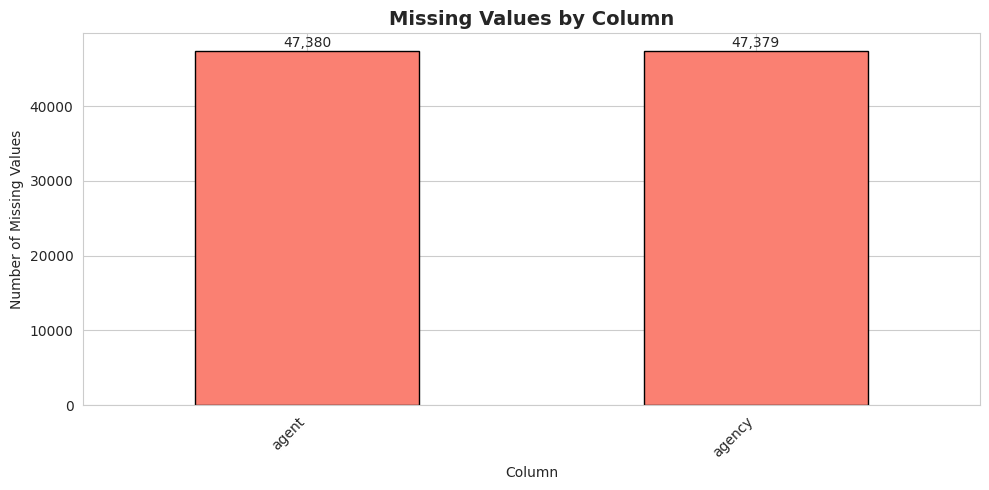

In [ ]:
# ──────────────────────────────────────────────
# 2.1  Calculate and visualize missing values
# ──────────────────────────────────────────────

# .isnull() returns True/False for each cell; .sum() counts the Trues
missing = df.isnull().sum()

# Filter to only columns that actually have missing data
missing_only = missing[missing > 0].sort_values(ascending=False)

print("Columns with missing values:\n")
for col, count in missing_only.items():
    pct = count / len(df) * 100
    print(f"  {col:20s} → {count:,} missing  ({pct:.1f}%)")

# Visualize with a bar chart
if len(missing_only) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    missing_only.plot(kind='bar', color='salmon', edgecolor='black', ax=ax)
    ax.set_title('Missing Values by Column', fontsize=14, fontweight='bold')
    ax.set_ylabel('Number of Missing Values')
    ax.set_xlabel('Column')

    # Add count labels on top of each bar
    for i, (col, val) in enumerate(missing_only.items()):
        ax.text(i, val + 500, f'{val:,}', ha='center', fontsize=10)

    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("\n🎉 No missing values found!")

**Observation:** The `agency` and `agent` columns have ~47,000 missing values (~25%). This makes sense — not every property listing on Zameen.com is posted through an agency; some are posted directly by owners.

### 2.2  Drop Irrelevant Columns

Some columns don't contribute to our analysis. We'll remove:
- `page_url` — just a web link, not useful for analysis
- `location_id` — a numeric ID that duplicates the `location` column

In [ ]:
# ──────────────────────────────────────────────
# 2.2  Drop columns we don't need
# ──────────────────────────────────────────────
# axis=1 means "drop COLUMNS" (axis=0 would drop rows)
# inplace=True modifies the DataFrame directly instead of returning a copy

print(f"Columns BEFORE dropping: {df.shape[1]}")

df.drop(columns=['page_url', 'location_id'], inplace=True)

print(f"Columns AFTER dropping:  {df.shape[1]}")
print(f"\nRemaining columns: {list(df.columns)}")

Columns BEFORE dropping: 17
Columns AFTER dropping:  15

Remaining columns: ['property_id', 'property_type', 'price', 'location', 'city', 'province_name', 'latitude', 'longitude', 'baths', 'area', 'purpose', 'bedrooms', 'date_added', 'agency', 'agent']


### 2.3  Imputation Strategy

"Imputation" means **filling in missing values with reasonable estimates**. Our strategy:

| Column Type | Fill With | Why |
|-------------|-----------|-----|
| **Categorical** (text) | `"Unknown"` | We can't guess an agency name, so we label it honestly |
| **Numerical** (numbers) | Column **mean** | The average is a safe neutral estimate that doesn't distort the distribution much |

In [ ]:
# ──────────────────────────────────────────────
# 2.3  Fill missing values
# ──────────────────────────────────────────────

# Step 1: Identify which columns are categorical (text) vs numerical
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
numerical_cols = df.select_dtypes(include=['number']).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

# Step 2: Fill categorical nulls with "Unknown"
for col in categorical_cols:
    null_count = df[col].isnull().sum()
    if null_count > 0:
        df[col].fillna('Unknown', inplace=True)
        print(f"  Filled {null_count:,} nulls in '{col}' with 'Unknown'")

# Step 3: Fill numerical nulls with the column's mean
for col in numerical_cols:
    null_count = df[col].isnull().sum()
    if null_count > 0:
        mean_val = df[col].mean()
        df[col].fillna(mean_val, inplace=True)
        print(f"  Filled {null_count:,} nulls in '{col}' with mean = {mean_val:.2f}")

Categorical columns: ['property_type', 'location', 'city', 'province_name', 'area', 'purpose', 'date_added', 'agency', 'agent']
Numerical columns: ['property_id', 'price', 'latitude', 'longitude', 'baths', 'bedrooms']
  Filled 47,379 nulls in 'agency' with 'Unknown'
  Filled 47,380 nulls in 'agent' with 'Unknown'


In [ ]:
# ──────────────────────────────────────────────
# 2.4  Verification — Confirm zero missing values
# ──────────────────────────────────────────────

total_missing = df.isnull().sum().sum()

if total_missing == 0:
    print("✅ Verification PASSED: Zero missing values remain in the dataset.")
else:
    print(f"⚠️ Still {total_missing} missing values — needs further investigation.")

✅ Verification PASSED: Zero missing values remain in the dataset.


### 2.5  Data Transformation — Standardize the `area` Column

The `area` column has **mixed units**: some values are in **Marla** (e.g., "10 Marla") and others in **Kanal** (e.g., "1 Kanal"). We need a single unit for fair comparisons.

**Conversion rule:** 1 Kanal = 20 Marla

Our approach:
1. Extract the **number** from the string (e.g., "10" from "10 Marla")
2. Extract the **unit** (Marla or Kanal)
3. If Kanal → multiply by 20 to convert to Marla
4. Store the result in a new column: `area_in_marla`

In [ ]:
# ──────────────────────────────────────────────
# 2.5  Convert area to a single unit (Marla)
# ──────────────────────────────────────────────

# Step 1: Extract the numeric part using a regular expression
# r'([\d.]+)' captures one or more digits (with optional decimal point)
# .astype(float) converts the extracted string to a number
df['area_numeric'] = df['area'].str.extract(r'([\d.]+)').astype(float)

# Step 2: Extract the unit (Kanal or Marla)
# This creates a Series of either 'Kanal' or 'Marla' for each row
df['area_unit'] = df['area'].str.extract(r'(Kanal|Marla)')

# Step 3: Apply the conversion logic
# np.where() works like an IF-ELSE:
#   IF area_unit == 'Kanal' → multiply by 20
#   ELSE → keep as is (already in Marla)
df['area_in_marla'] = np.where(
    df['area_unit'] == 'Kanal',
    df['area_numeric'] * 20,   # Kanal → Marla conversion
    df['area_numeric']          # Already in Marla, no change
)

# Step 4: Drop the temporary helper columns — we only need area_in_marla
df.drop(columns=['area_numeric', 'area_unit'], inplace=True)

# Verify the conversion with a few examples
print("Sample area conversions:\n")
print(df[['area', 'area_in_marla']].head(10).to_string(index=False))
print(f"\n✅ New column 'area_in_marla' created. Non-null count: {df['area_in_marla'].notna().sum():,}")

Sample area conversions:

     area  area_in_marla
  6 Kanal          120.0
  1 Kanal           20.0
  9 Marla            9.0
  1 Kanal           20.0
 11 Marla           11.0
  1 Kanal           20.0
  8 Marla            8.0
  1 Kanal           20.0
  1 Kanal           20.0
1.6 Kanal           32.0

✅ New column 'area_in_marla' created. Non-null count: 191,393


### 2.6  Extract Temporal Features from `date_added`

The `date_added` column is a string like "07-17-2019". We'll convert it to a proper datetime and extract **year** and **month** for time-based analysis later.

In [ ]:
# ──────────────────────────────────────────────
# 2.6  Parse dates and extract year/month
# ──────────────────────────────────────────────

# Convert the string to a datetime object
# format='%m-%d-%Y' tells pandas the format is Month-Day-Year
# errors='coerce' turns unparseable dates into NaT (Not a Time) instead of crashing
df['date_added'] = pd.to_datetime(df['date_added'], format='%m-%d-%Y', errors='coerce')

# Extract year and month into their own columns
df['year'] = df['date_added'].dt.year
df['month'] = df['date_added'].dt.month

print("Date range in dataset:")
print(f"  Earliest listing: {df['date_added'].min()}")
print(f"  Latest listing:   {df['date_added'].max()}")
print(f"\nYear distribution:")
print(df['year'].value_counts().sort_index())

Date range in dataset:
  Earliest listing: 2018-08-05 00:00:00
  Latest listing:   2019-08-06 00:00:00

Year distribution:
year
2018     12309
2019    179084
Name: count, dtype: int64


---
## Phase 3: Outlier Detection

Outliers are **extreme values** that don't fit the general pattern. In real estate data, outliers might be:
- A house listed at **0 PKR** (likely a data entry error)
- A property with **0 Marla** area (impossible)
- A flat priced at **billions of PKR** (could be legit luxury or a typo)

We use **boxplots** and **scatter plots** to visually spot these anomalies.

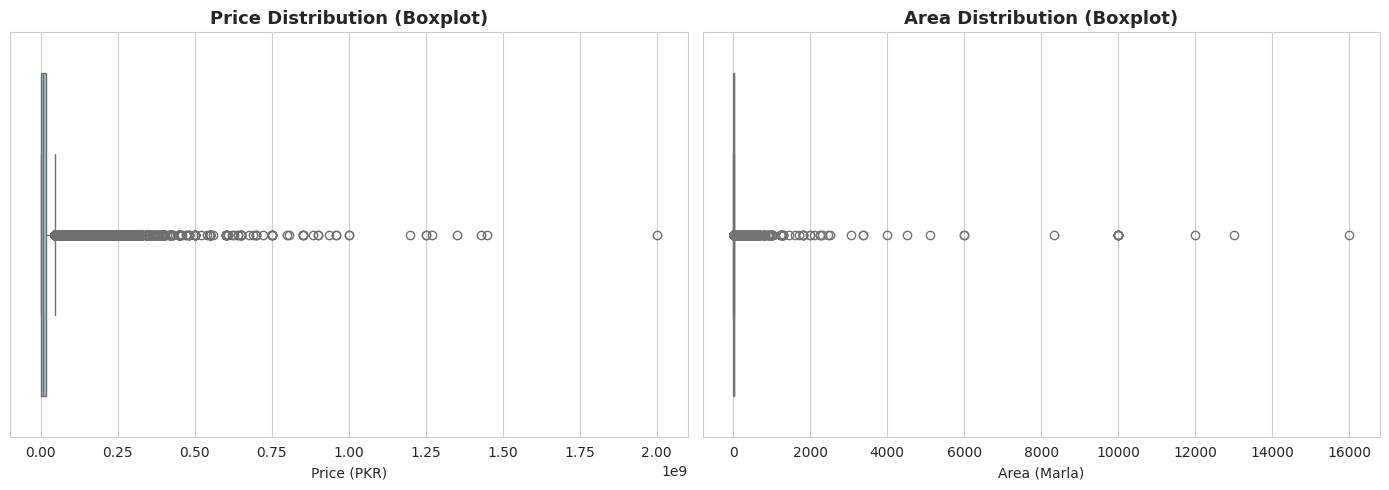

price: 16,818 outliers detected (IQR method)
area_in_marla: 11,057 outliers detected (IQR method)


In [ ]:
# ──────────────────────────────────────────────
# 3.1  Boxplots for Price and Area
# ──────────────────────────────────────────────
# A boxplot shows the median, quartiles, and outliers.
# The "whiskers" extend to 1.5× the IQR (interquartile range).
# Any points beyond the whiskers are plotted as individual dots = OUTLIERS.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Price boxplot
sns.boxplot(x=df['price'], ax=axes[0], color='skyblue')
axes[0].set_title('Price Distribution (Boxplot)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price (PKR)')

# Area boxplot
sns.boxplot(x=df['area_in_marla'], ax=axes[1], color='lightgreen')
axes[1].set_title('Area Distribution (Boxplot)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Area (Marla)')

plt.tight_layout()
plt.show()

# Print outlier counts using IQR method
for col_name, col_data in [('price', df['price']), ('area_in_marla', df['area_in_marla'])]:
    Q1 = col_data.quantile(0.25)
    Q3 = col_data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = col_data[(col_data < lower_bound) | (col_data > upper_bound)]
    print(f"{col_name}: {len(outliers):,} outliers detected (IQR method)")

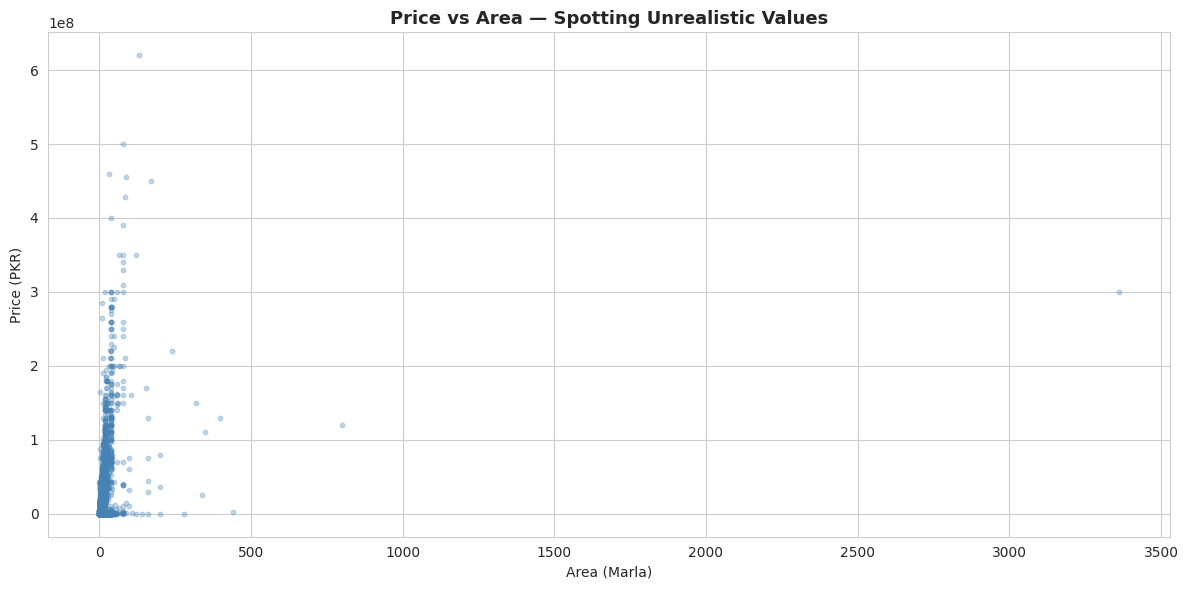

Properties with price = 0:  3
Properties with area  = 0:  16


In [ ]:
# ──────────────────────────────────────────────
# 3.2  Scatter plot to spot unrealistic values
# ──────────────────────────────────────────────
# We look for: tiny area + huge price (errors?) or huge area + tiny price (errors?)

fig, ax = plt.subplots(figsize=(12, 6))

# Use a sample of 10,000 points for faster rendering
sample = df.sample(n=min(10000, len(df)), random_state=42)

ax.scatter(sample['area_in_marla'], sample['price'],
           alpha=0.3, s=10, color='steelblue')
ax.set_title('Price vs Area — Spotting Unrealistic Values', fontsize=13, fontweight='bold')
ax.set_xlabel('Area (Marla)')
ax.set_ylabel('Price (PKR)')

plt.tight_layout()
plt.show()

# Flag suspicious records
zero_price = df[df['price'] == 0].shape[0]
zero_area = df[df['area_in_marla'] == 0].shape[0]
print(f"Properties with price = 0:  {zero_price:,}")
print(f"Properties with area  = 0:  {zero_area:,}")

---
## Phase 4: Exploratory Data Analysis (EDA)

EDA is the heart of any data science project. We ask questions of the data and let **visualizations** reveal the answers. We'll cover three levels:
- **Univariate** — one variable at a time
- **Bivariate** — relationship between two variables
- **Multivariate** — three or more variables together

---
### A. Univariate Analysis (One Variable)

#### Q1: Price Distribution — Is it normally distributed or skewed?

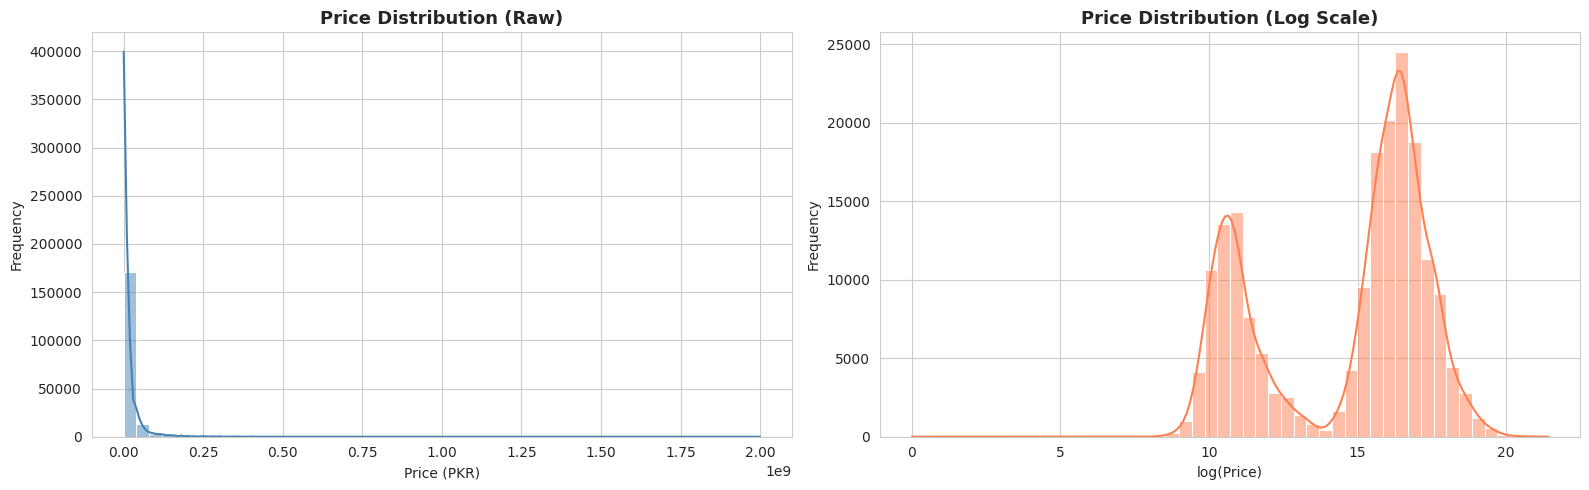

📊 Insight: The raw price distribution is HIGHLY RIGHT-SKEWED
   (a few extremely expensive properties stretch the tail).
   The log-transformed version looks much closer to a normal (bell) curve.


In [ ]:
# ──────────────────────────────────────────────
# 4.1  Price Distribution — Histogram with KDE
# ──────────────────────────────────────────────
# KDE = Kernel Density Estimation — a smooth curve that estimates
# the probability distribution of the data.

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: Raw price distribution
sns.histplot(df['price'], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Price Distribution (Raw)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price (PKR)')
axes[0].set_ylabel('Frequency')

# Right: Log-transformed price
# np.log1p() = log(1 + x) — avoids log(0) errors
# Log transform compresses the scale, revealing the TRUE shape of the distribution
sns.histplot(np.log1p(df['price']), bins=50, kde=True, ax=axes[1], color='coral')
axes[1].set_title('Price Distribution (Log Scale)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('log(Price)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

print("📊 Insight: The raw price distribution is HIGHLY RIGHT-SKEWED")
print("   (a few extremely expensive properties stretch the tail).")
print("   The log-transformed version looks much closer to a normal (bell) curve.")

#### Q2: Property Type Counts — Which type is most common?

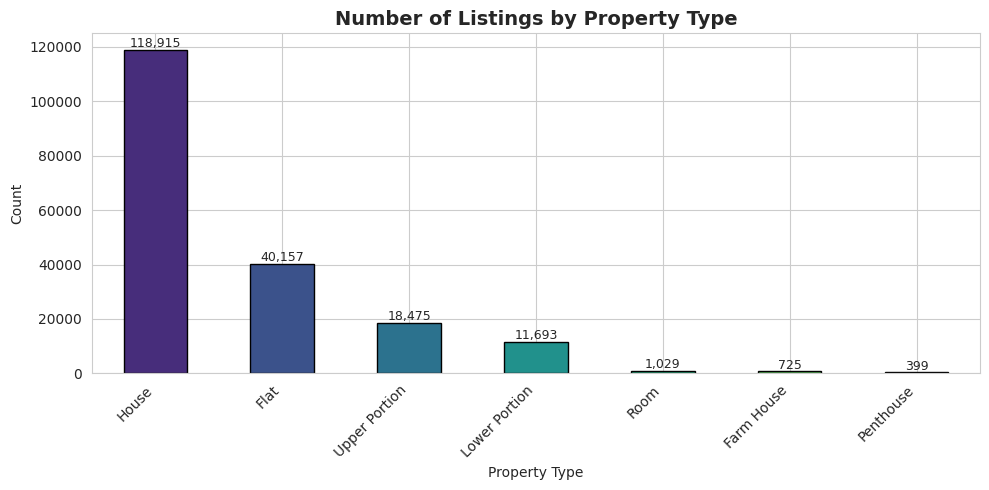

📊 Most common property type: 'House' with 118,915 listings.


In [ ]:
# ──────────────────────────────────────────────
# 4.2  Property Type Counts — Bar Chart
# ──────────────────────────────────────────────
# value_counts() counts how many times each category appears

type_counts = df['property_type'].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
bars = type_counts.plot(kind='bar', color=sns.color_palette('viridis', len(type_counts)),
                        edgecolor='black', ax=ax)
ax.set_title('Number of Listings by Property Type', fontsize=14, fontweight='bold')
ax.set_xlabel('Property Type')
ax.set_ylabel('Count')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

# Add count labels on each bar
for i, (val, name) in enumerate(zip(type_counts.values, type_counts.index)):
    ax.text(i, val + 1000, f'{val:,}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

print(f"📊 Most common property type: '{type_counts.index[0]}' with {type_counts.values[0]:,} listings.")

#### Q3: City Representation — Top 5 cities by listing count

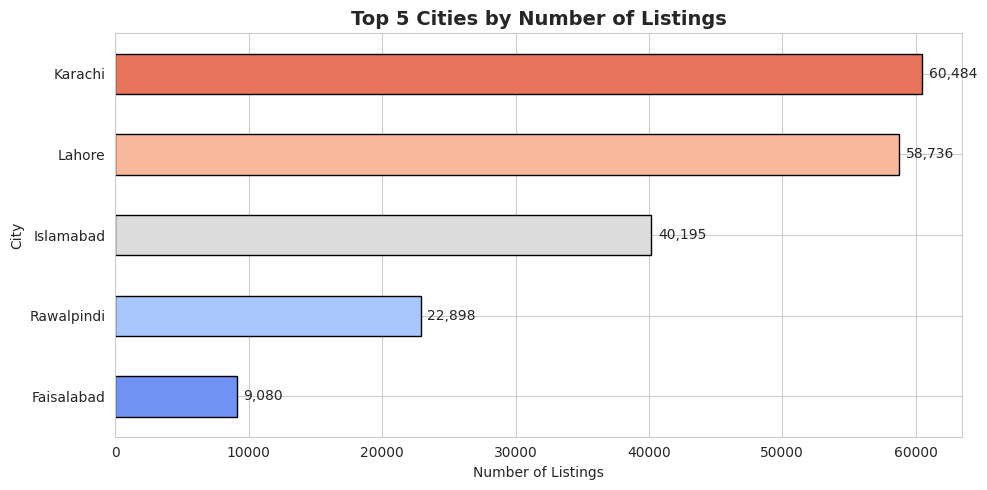

In [ ]:
# ──────────────────────────────────────────────
# 4.3  Top 5 Cities — Horizontal Bar Chart
# ──────────────────────────────────────────────
# A horizontal bar chart is better when category labels are long

top_cities = df['city'].value_counts().head(5)

fig, ax = plt.subplots(figsize=(10, 5))
top_cities.sort_values().plot(kind='barh', color=sns.color_palette('coolwarm', 5),
                               edgecolor='black', ax=ax)
ax.set_title('Top 5 Cities by Number of Listings', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Listings')
ax.set_ylabel('City')

# Add count labels at the end of each bar
for i, val in enumerate(top_cities.sort_values().values):
    ax.text(val + 500, i, f'{val:,}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

#### Q4: Area Distribution — Are there extreme values?

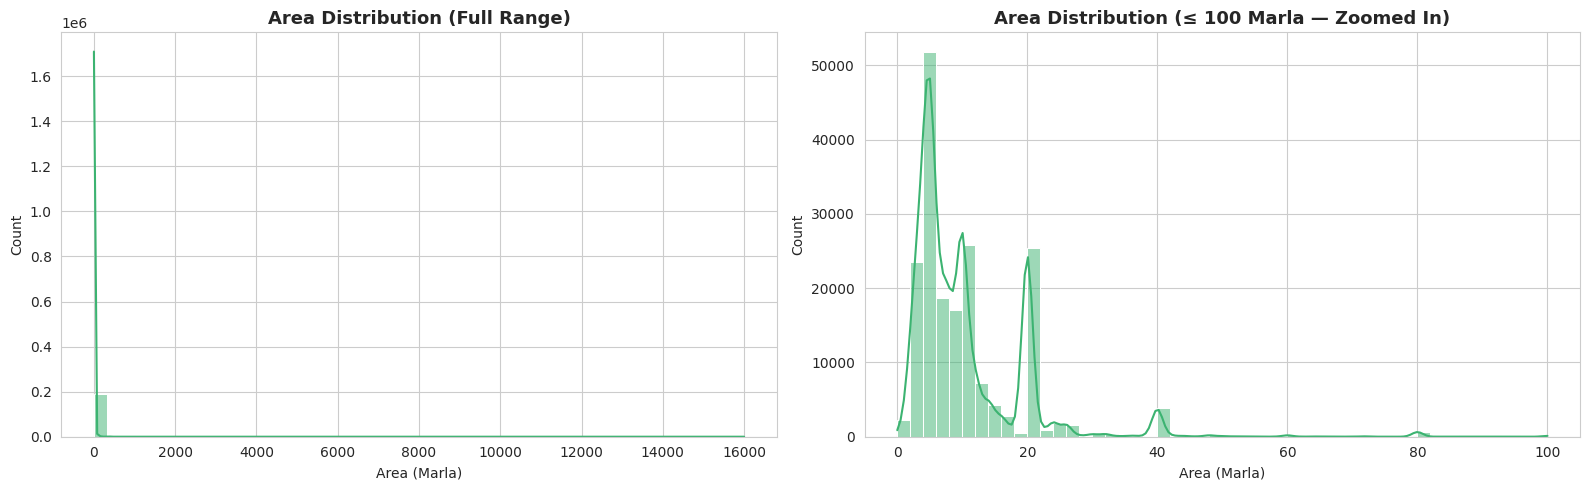

Max area: 16,000 Marla
Properties > 100 Marla: 668 (0.3%)
Most properties are concentrated under 20 Marla (1 Kanal).


In [ ]:
# ──────────────────────────────────────────────
# 4.4  Area Distribution
# ──────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: Full distribution (will be skewed by extreme values)
sns.histplot(df['area_in_marla'], bins=50, kde=True, ax=axes[0], color='mediumseagreen')
axes[0].set_title('Area Distribution (Full Range)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Area (Marla)')

# Right: Zoomed in to <= 100 Marla (where most properties are)
# This removes extreme farmhouses/commercial plots so we can see the real pattern
reasonable = df[df['area_in_marla'] <= 100]
sns.histplot(reasonable['area_in_marla'], bins=50, kde=True, ax=axes[1], color='mediumseagreen')
axes[1].set_title('Area Distribution (≤ 100 Marla — Zoomed In)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Area (Marla)')

plt.tight_layout()
plt.show()

print(f"Max area: {df['area_in_marla'].max():,.0f} Marla")
print(f"Properties > 100 Marla: {(df['area_in_marla'] > 100).sum():,} ({(df['area_in_marla'] > 100).mean()*100:.1f}%)")
print(f"Most properties are concentrated under 20 Marla (1 Kanal).")

---
### B. Bivariate Analysis (Two Variables)

#### Q5: Price vs. Location (Top 3 Cities) — Which city is most expensive?

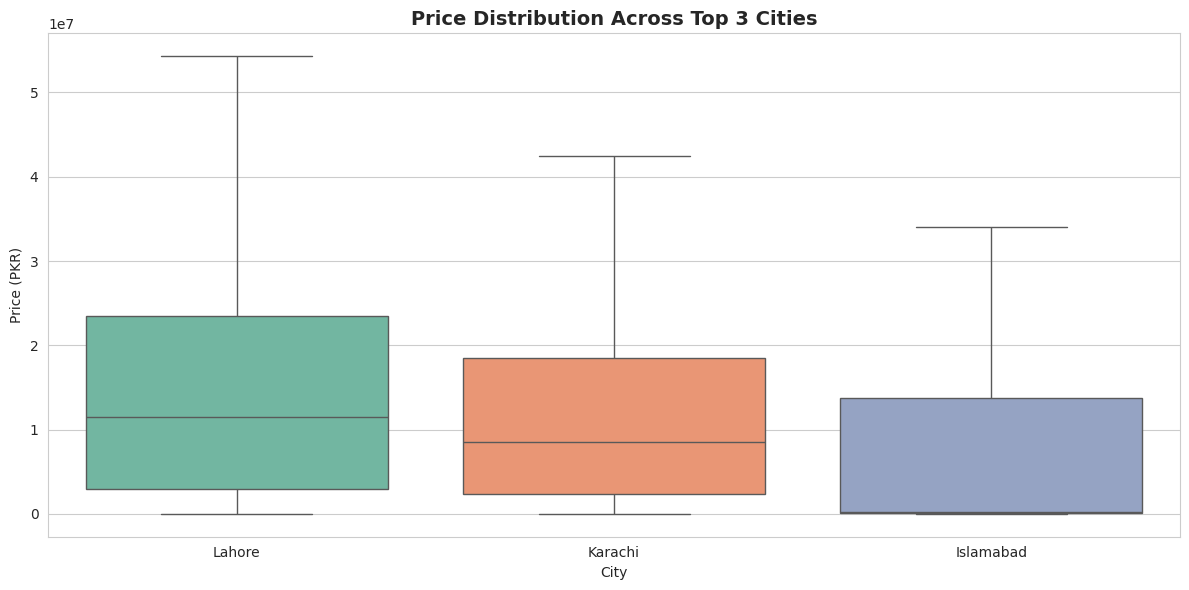

Median prices by city:
  Karachi: 8,500,000 PKR
  Lahore: 11,500,000 PKR
  Islamabad: 240,000 PKR


In [ ]:
# ──────────────────────────────────────────────
# 4.5  Price vs City — Boxplot (top 3 cities)
# ──────────────────────────────────────────────
# A boxplot per city lets us compare median prices, spread, and outliers.

top3_cities = df['city'].value_counts().head(3).index.tolist()
df_top3 = df[df['city'].isin(top3_cities)]

fig, ax = plt.subplots(figsize=(12, 6))

# showfliers=False hides outlier dots (they'd overwhelm the plot)
sns.boxplot(x='city', y='price', data=df_top3,
            palette='Set2', ax=ax, showfliers=False)
ax.set_title('Price Distribution Across Top 3 Cities', fontsize=14, fontweight='bold')
ax.set_xlabel('City')
ax.set_ylabel('Price (PKR)')

plt.tight_layout()
plt.show()

# Print median prices for comparison
print("Median prices by city:")
for city in top3_cities:
    median = df[df['city'] == city]['price'].median()
    print(f"  {city}: {median:,.0f} PKR")

#### Q6: Price vs. Area — Does bigger mean more expensive?

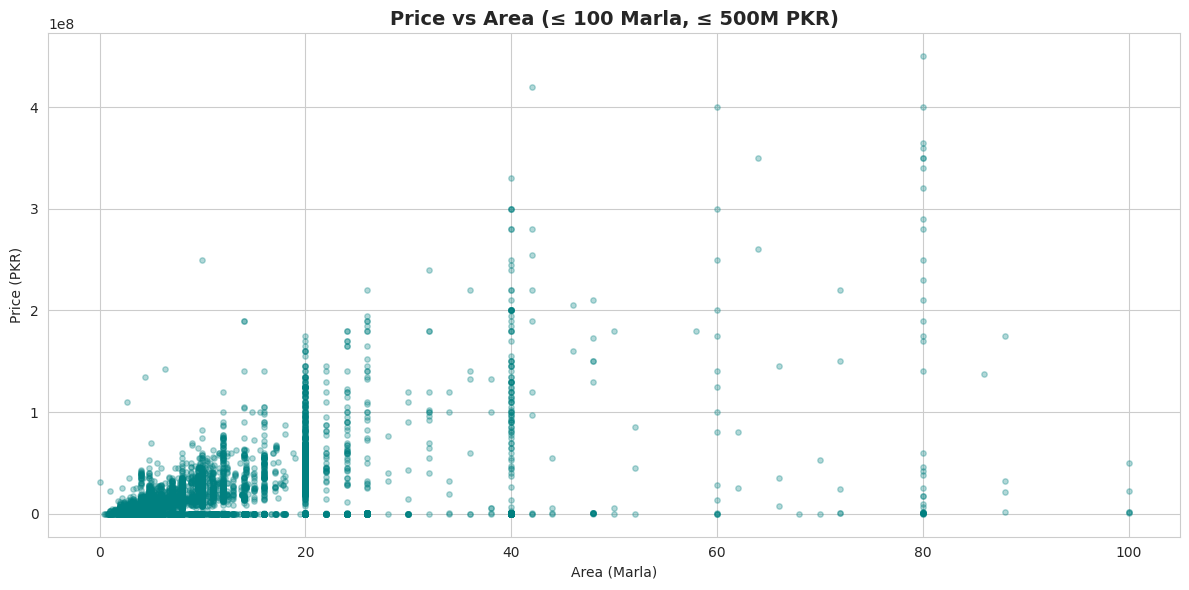

📊 Insight: There IS a positive relationship — larger properties generally cost more.
   But the relationship is NOT perfectly linear; there's wide price variation
   at every size level, driven by location, property type, and condition.


In [ ]:
# ──────────────────────────────────────────────
# 4.6  Price vs Area — Scatter Plot
# ──────────────────────────────────────────────
# We expect a positive relationship: bigger area → higher price.
# But some outliers may break this pattern.

# Filter to reasonable ranges to make the plot readable
mask = (df['area_in_marla'] <= 100) & (df['price'] <= 500_000_000)
filtered = df[mask].sample(n=min(10000, mask.sum()), random_state=42)

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(filtered['area_in_marla'], filtered['price'],
           alpha=0.3, s=15, color='teal')
ax.set_title('Price vs Area (≤ 100 Marla, ≤ 500M PKR)', fontsize=14, fontweight='bold')
ax.set_xlabel('Area (Marla)')
ax.set_ylabel('Price (PKR)')

plt.tight_layout()
plt.show()

print("📊 Insight: There IS a positive relationship — larger properties generally cost more.")
print("   But the relationship is NOT perfectly linear; there's wide price variation")
print("   at every size level, driven by location, property type, and condition.")

#### Q7: Bathrooms vs. Price — Do more baths mean higher prices?

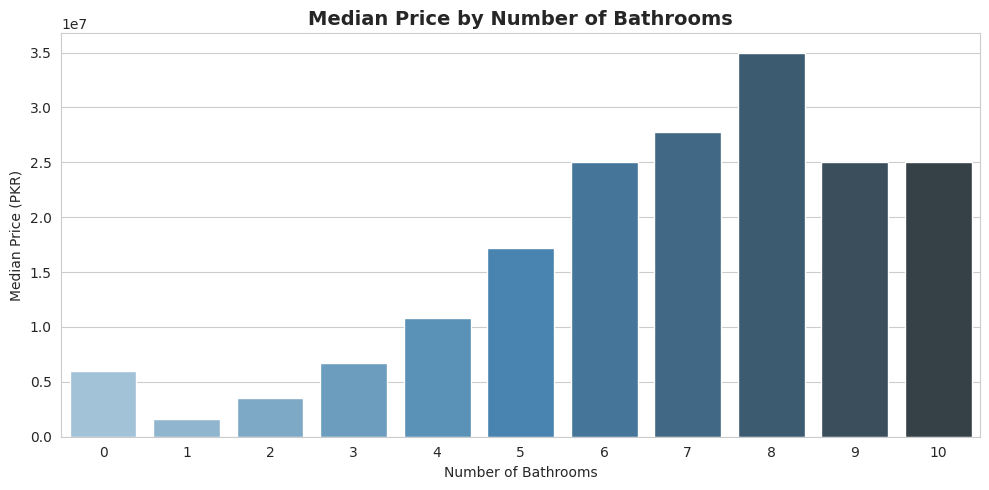

📊 Insight: Yes — more bathrooms correlate with higher prices.
   This makes sense because more baths usually means a larger, more premium property.


In [ ]:
# ──────────────────────────────────────────────
# 4.7  Bathrooms vs Price
# ──────────────────────────────────────────────

# Group by number of baths and compute median price
bath_price = df.groupby('baths')['price'].median().reset_index()
bath_price = bath_price[bath_price['baths'] <= 10]  # Focus on realistic values

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x='baths', y='price', data=bath_price, palette='Blues_d', ax=ax)
ax.set_title('Median Price by Number of Bathrooms', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Bathrooms')
ax.set_ylabel('Median Price (PKR)')

plt.tight_layout()
plt.show()

print("📊 Insight: Yes — more bathrooms correlate with higher prices.")
print("   This makes sense because more baths usually means a larger, more premium property.")

#### Q8: Listings Over Time — How has the market grown?

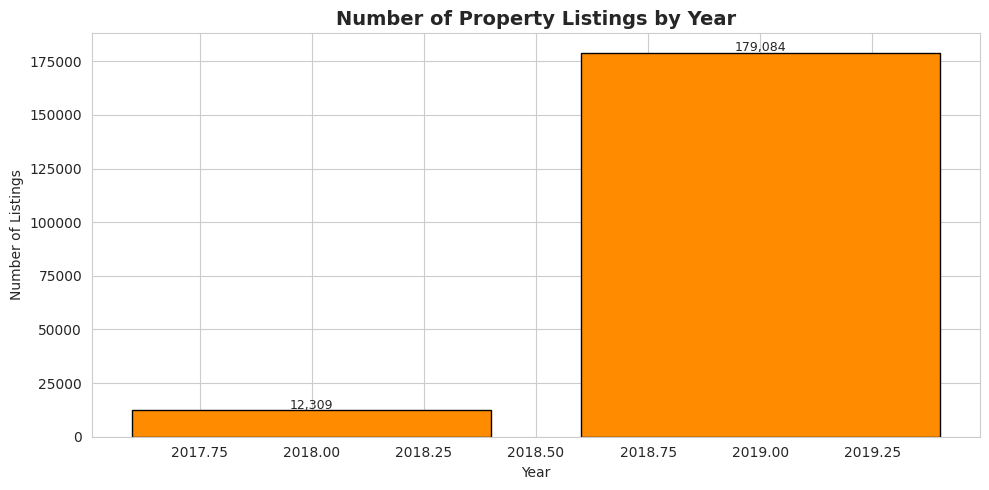

In [ ]:
# ──────────────────────────────────────────────
# 4.8  Number of listings per year
# ──────────────────────────────────────────────

yearly_counts = df.groupby('year').size().reset_index(name='count')
yearly_counts = yearly_counts.dropna()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(yearly_counts['year'], yearly_counts['count'],
       color='darkorange', edgecolor='black')
ax.set_title('Number of Property Listings by Year', fontsize=14, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Number of Listings')

# Add count labels
for _, row in yearly_counts.iterrows():
    ax.text(row['year'], row['count'] + 500, f"{int(row['count']):,}",
            ha='center', fontsize=9)

plt.tight_layout()
plt.show()

---
### C. Multivariate Analysis (Three+ Variables)

#### Q9: Price vs. Area, colored by City — Do same-size properties cost different amounts in different cities?

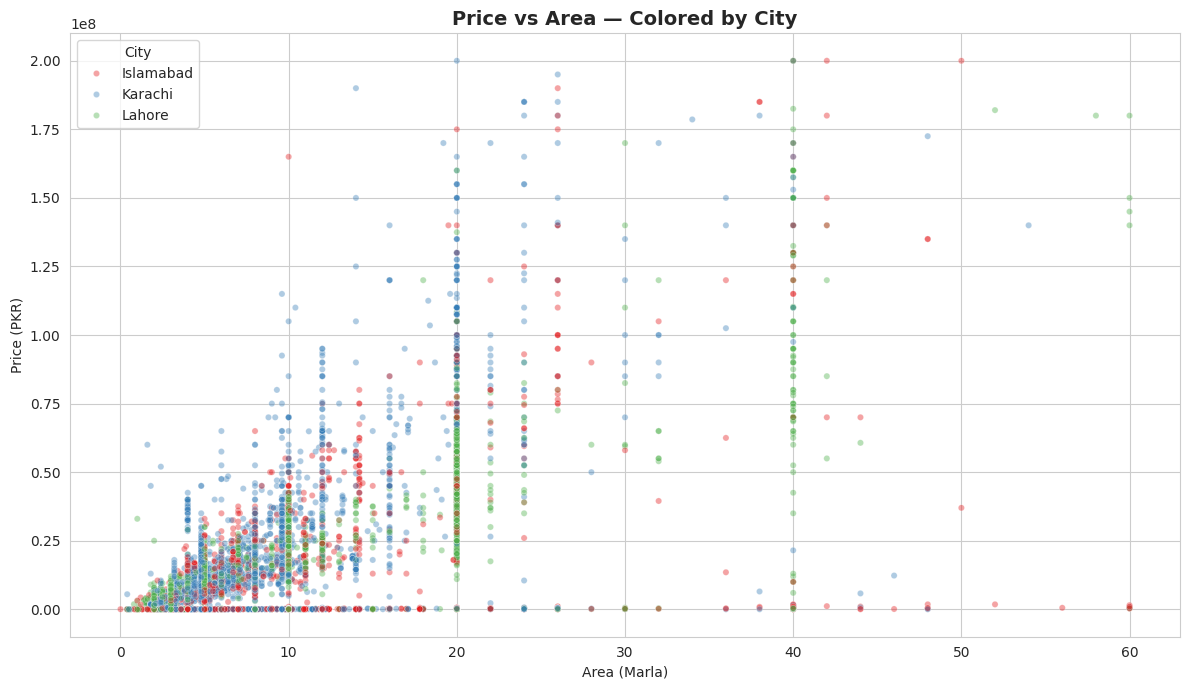

📊 Insight: For the same area, Islamabad and Lahore properties tend to be priced
   higher than Karachi. Location is a major price driver beyond just size.


In [ ]:
# ──────────────────────────────────────────────
# 4.9  Price vs Area by City (multivariate scatter)
# ──────────────────────────────────────────────
# The 'hue' parameter colors each point by city, revealing
# whether location affects the price-area relationship.

mask = (df['area_in_marla'] <= 60) & (df['price'] <= 200_000_000)
top3 = df[mask & df['city'].isin(top3_cities)]
sample_multi = top3.sample(n=min(10000, len(top3)), random_state=42)

fig, ax = plt.subplots(figsize=(12, 7))
sns.scatterplot(x='area_in_marla', y='price', hue='city',
                data=sample_multi, alpha=0.4, s=20, palette='Set1', ax=ax)
ax.set_title('Price vs Area — Colored by City', fontsize=14, fontweight='bold')
ax.set_xlabel('Area (Marla)')
ax.set_ylabel('Price (PKR)')
ax.legend(title='City')

plt.tight_layout()
plt.show()

print("📊 Insight: For the same area, Islamabad and Lahore properties tend to be priced")
print("   higher than Karachi. Location is a major price driver beyond just size.")

#### Q10: Correlation Matrix — Which numerical features are most related?

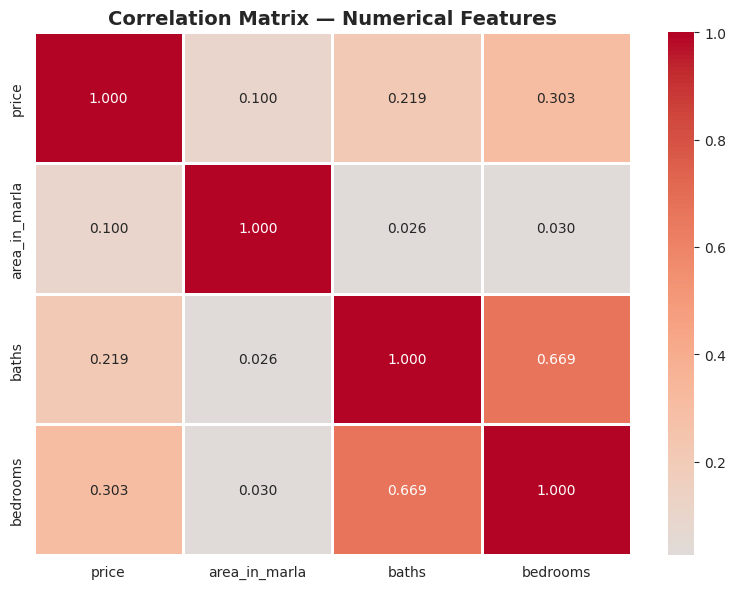


Strongest positive correlation with price: 'bedrooms' (r = 0.303)


In [ ]:
# ──────────────────────────────────────────────
# 4.10  Correlation Heatmap
# ──────────────────────────────────────────────
# A correlation matrix measures how strongly pairs of variables move together.
# Values range from -1 (perfect negative) to +1 (perfect positive).
# 0 means no linear relationship.

corr_cols = ['price', 'area_in_marla', 'baths', 'bedrooms']
correlation_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            fmt='.3f', linewidths=1, linecolor='white', ax=ax)
ax.set_title('Correlation Matrix — Numerical Features', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Find the variable most correlated with price (excluding price itself)
price_corr = correlation_matrix['price'].drop('price').sort_values(ascending=False)
print(f"\nStrongest positive correlation with price: '{price_corr.index[0]}' (r = {price_corr.values[0]:.3f})")

#### Q11: Average Price by Property Type, split by Purpose (Sale vs. Rent)

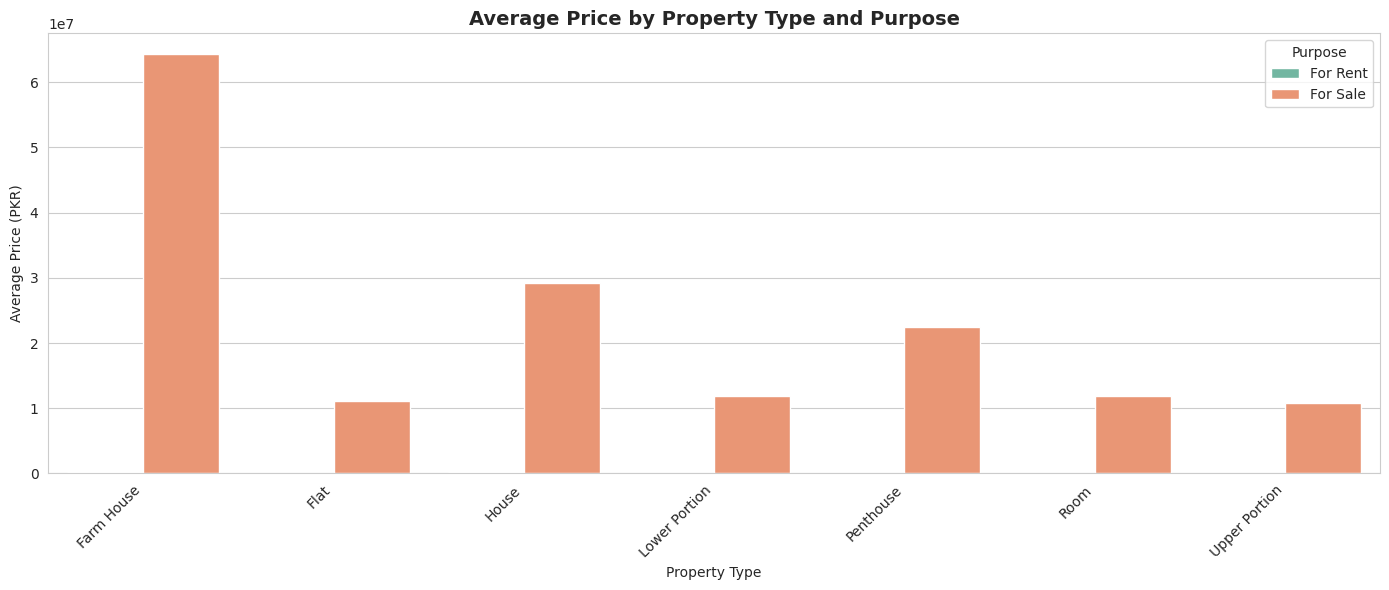

📊 Insight: Sale prices are dramatically higher than rental prices across all types.
   Farm Houses and Houses have the highest average sale prices.


In [ ]:
# ──────────────────────────────────────────────
# 4.11  Grouped bar chart — Property Type × Purpose
# ──────────────────────────────────────────────
# This shows how SALE vs RENT prices compare across property types.

avg_price = df.groupby(['property_type', 'purpose'])['price'].mean().reset_index()

fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(x='property_type', y='price', hue='purpose',
            data=avg_price, palette='Set2', ax=ax)
ax.set_title('Average Price by Property Type and Purpose', fontsize=14, fontweight='bold')
ax.set_xlabel('Property Type')
ax.set_ylabel('Average Price (PKR)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.legend(title='Purpose')

plt.tight_layout()
plt.show()

print("📊 Insight: Sale prices are dramatically higher than rental prices across all types.")
print("   Farm Houses and Houses have the highest average sale prices.")

---
## Phase 5: Business Questions (Q&A)

Now we apply our analysis skills to answer **10 specific business questions** that would matter to investors, agencies, and buyers.

---

### BQ1: Which city shows the highest growth in high-value properties over the years?

We define "high-value" as properties priced above the **75th percentile** of all prices. Then we count how many high-value properties each city has per year and look at the growth trend.

High-value threshold (75th percentile): 18,000,000 PKR



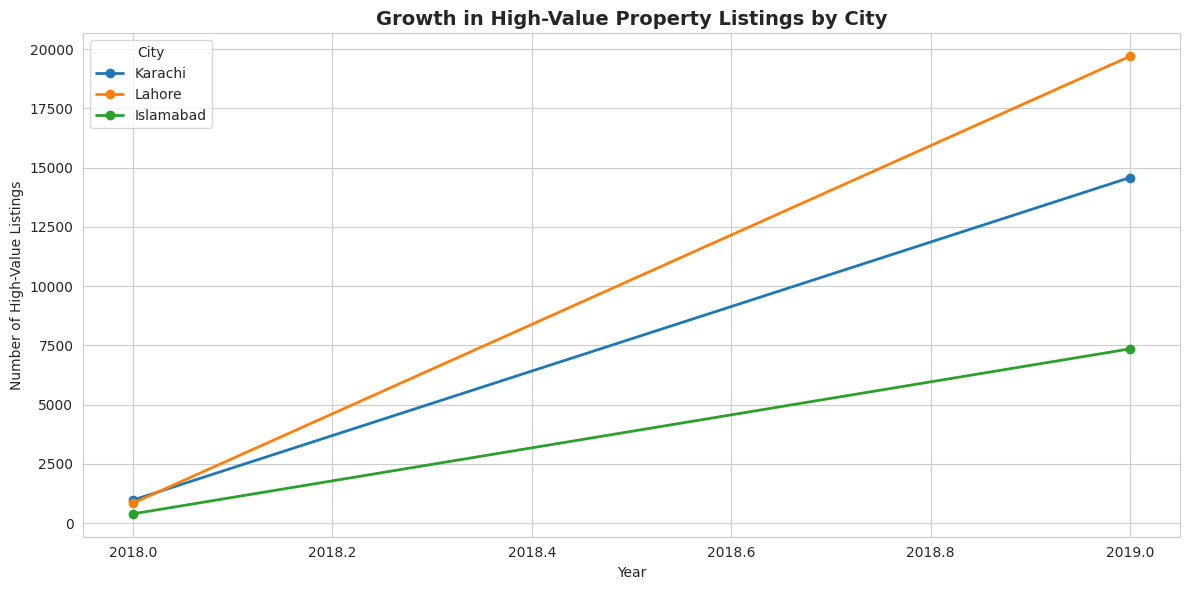

  Karachi: 974 → 14586 listings (growth: +1397.5%)
  Lahore: 843 → 19705 listings (growth: +2237.5%)
  Islamabad: 392 → 7356 listings (growth: +1776.5%)


In [ ]:
# ──────────────────────────────────────────────
# BQ1: Growth in high-value properties by city
# ──────────────────────────────────────────────

# Define "high-value" threshold as the 75th percentile
threshold = df['price'].quantile(0.75)
print(f"High-value threshold (75th percentile): {threshold:,.0f} PKR\n")

# Filter to high-value properties
high_value = df[df['price'] >= threshold]

# Count high-value listings per city per year
hv_growth = high_value.groupby(['year', 'city']).size().reset_index(name='count')

# Plot trends for top 3 cities
fig, ax = plt.subplots(figsize=(12, 6))
for city in top3_cities:
    city_data = hv_growth[hv_growth['city'] == city]
    ax.plot(city_data['year'], city_data['count'], marker='o', linewidth=2, label=city)

ax.set_title('Growth in High-Value Property Listings by City', fontsize=14, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Number of High-Value Listings')
ax.legend(title='City')

plt.tight_layout()
plt.show()

# Calculate overall growth
for city in top3_cities:
    city_data = hv_growth[hv_growth['city'] == city].sort_values('year')
    if len(city_data) >= 2:
        first_year = city_data.iloc[0]['count']
        last_year = city_data.iloc[-1]['count']
        growth = ((last_year - first_year) / first_year * 100) if first_year > 0 else 0
        print(f"  {city}: {first_year} → {last_year} listings (growth: {growth:+.1f}%)")

### BQ2: Most popular property types in each city and how preferences changed over time

Most Popular Property Type by City (Overall):

  Lahore          → House (49,423 listings)
  Karachi         → Flat (27,001 listings)
  Islamabad       → House (21,280 listings)
  Faisalabad      → House (7,645 listings)
  Rawalpindi      → House (15,308 listings)


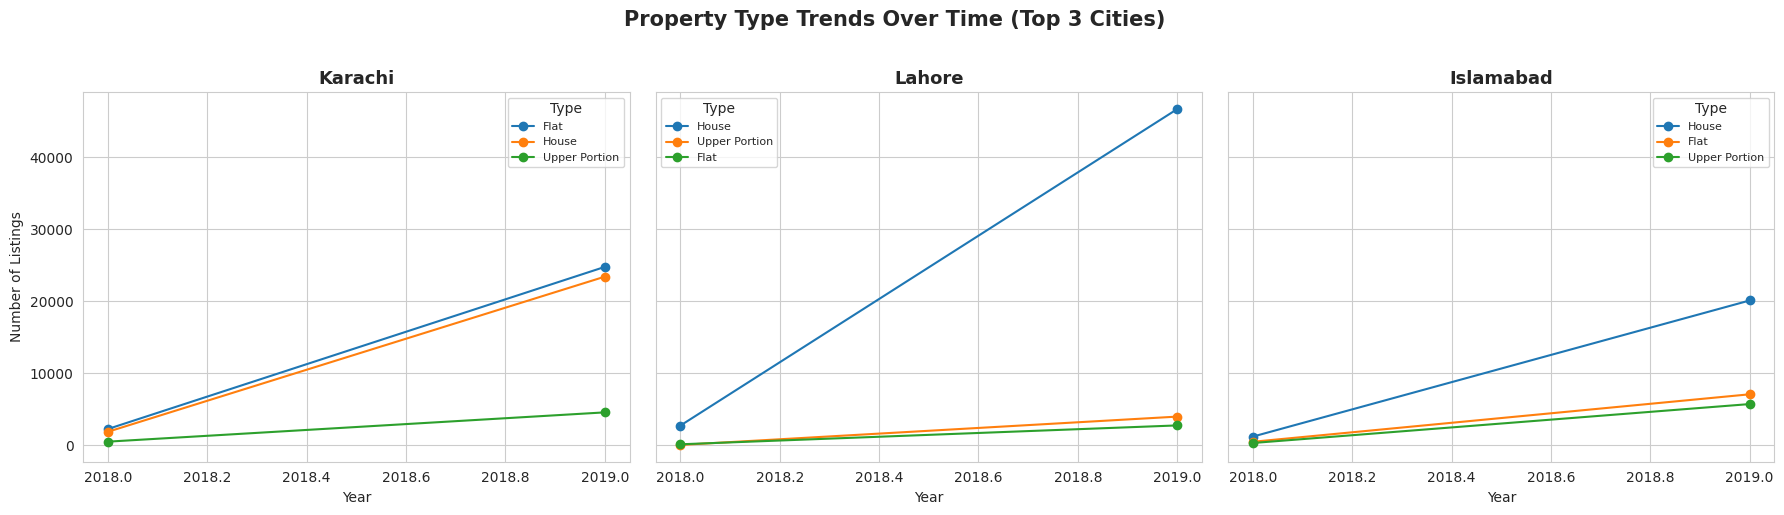

In [ ]:
# ──────────────────────────────────────────────
# BQ2: Popular property types by city and year
# ──────────────────────────────────────────────

# Current snapshot — most popular type per city
print("Most Popular Property Type by City (Overall):\n")
for city in df['city'].unique():
    top_type = df[df['city'] == city]['property_type'].value_counts().index[0]
    count = df[df['city'] == city]['property_type'].value_counts().values[0]
    print(f"  {city:15s} → {top_type} ({count:,} listings)")

# Trend over time — top 3 cities
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for i, city in enumerate(top3_cities):
    city_data = df[df['city'] == city]
    trend = city_data.groupby(['year', 'property_type']).size().reset_index(name='count')
    pivot = trend.pivot_table(index='year', columns='property_type', values='count', fill_value=0)

    # Plot only top 3 types to avoid clutter
    top_types = city_data['property_type'].value_counts().head(3).index
    pivot[top_types].plot(ax=axes[i], marker='o', linewidth=1.5)
    axes[i].set_title(f'{city}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Year')
    if i == 0:
        axes[i].set_ylabel('Number of Listings')
    axes[i].legend(fontsize=8, title='Type')

plt.suptitle('Property Type Trends Over Time (Top 3 Cities)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### BQ3: How do property prices vary with bedrooms across cities and property types?

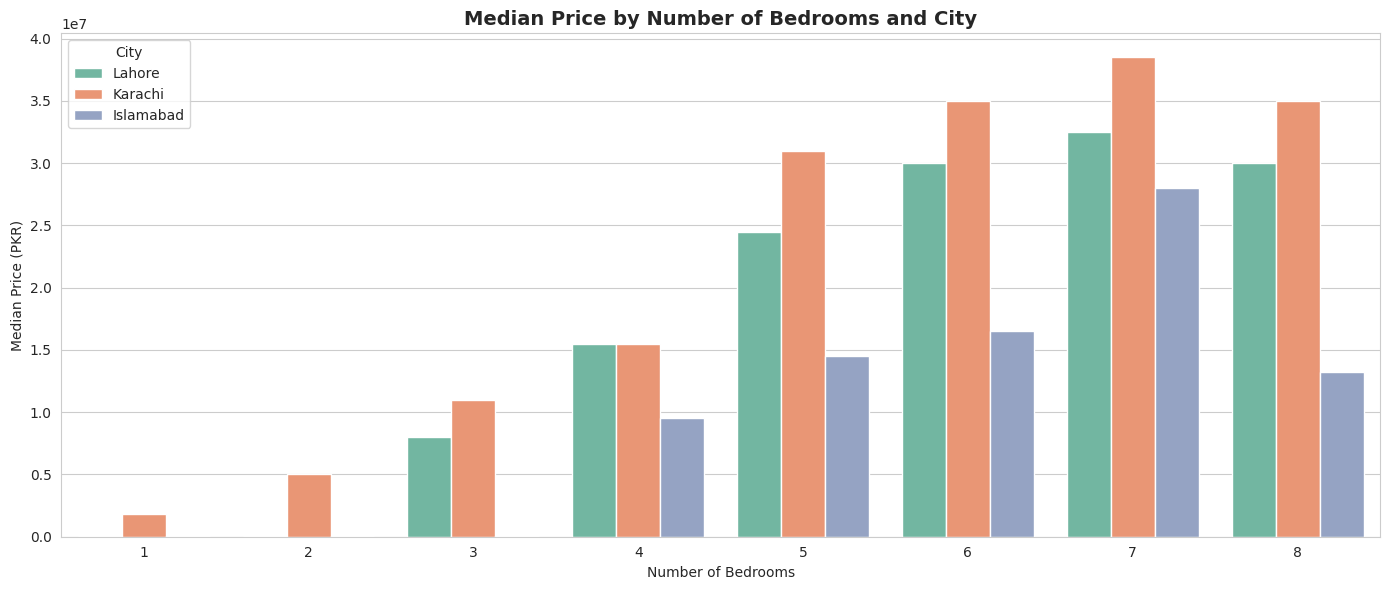

📊 Insight: More bedrooms = higher prices across all cities.
   Islamabad tends to have higher prices at each bedroom count.


In [ ]:
# ──────────────────────────────────────────────
# BQ3: Price vs Bedrooms across cities
# ──────────────────────────────────────────────

# Filter to reasonable bedroom counts (1-8) and top 3 cities
mask = (df['bedrooms'] >= 1) & (df['bedrooms'] <= 8) & (df['city'].isin(top3_cities))
bed_data = df[mask]

fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(x='bedrooms', y='price', hue='city', data=bed_data,
            palette='Set2', ax=ax, ci=None, estimator=np.median)
ax.set_title('Median Price by Number of Bedrooms and City', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Bedrooms')
ax.set_ylabel('Median Price (PKR)')
ax.legend(title='City')

plt.tight_layout()
plt.show()

print("📊 Insight: More bedrooms = higher prices across all cities.")
print("   Islamabad tends to have higher prices at each bedroom count.")

### BQ4: Which agencies have the most listings in high-demand areas?

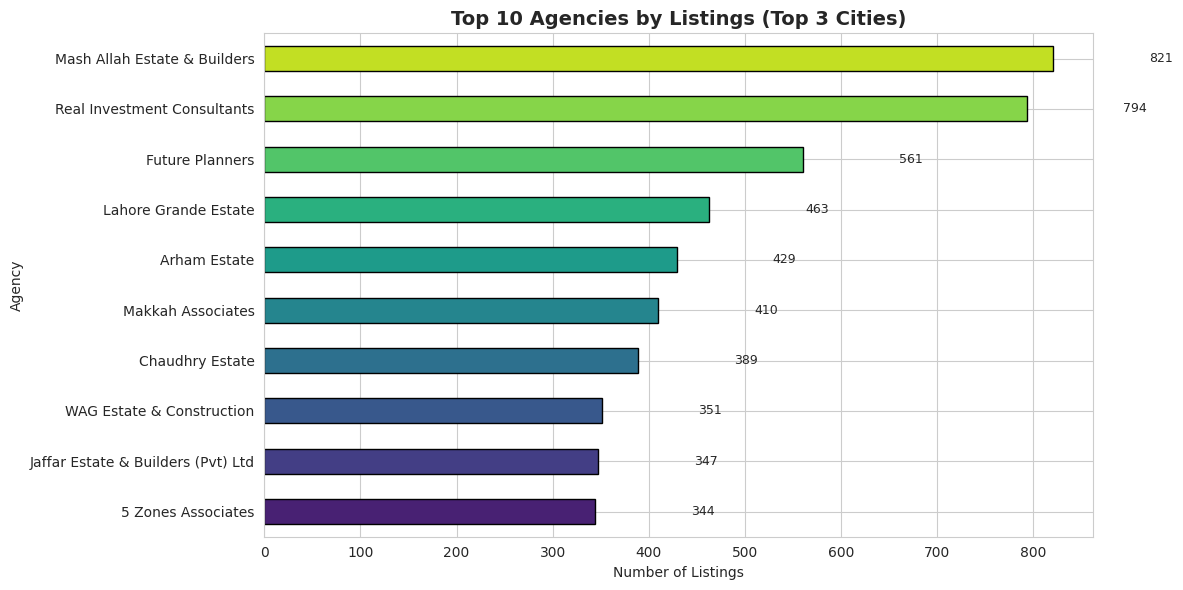

In [ ]:
# ──────────────────────────────────────────────
# BQ4: Top agencies in high-demand cities
# ──────────────────────────────────────────────

# Filter out 'Unknown' agencies and focus on top 3 cities
agency_df = df[(df['agency'] != 'Unknown') & (df['city'].isin(top3_cities))]

# Top 10 agencies overall
top_agencies = agency_df['agency'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(12, 6))
top_agencies.sort_values().plot(kind='barh', color=sns.color_palette('viridis', 10),
                                 edgecolor='black', ax=ax)
ax.set_title('Top 10 Agencies by Listings (Top 3 Cities)', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Listings')
ax.set_ylabel('Agency')

for i, val in enumerate(top_agencies.sort_values().values):
    ax.text(val + 100, i, f'{val:,}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

### BQ5: Is there a seasonal trend in property listings?

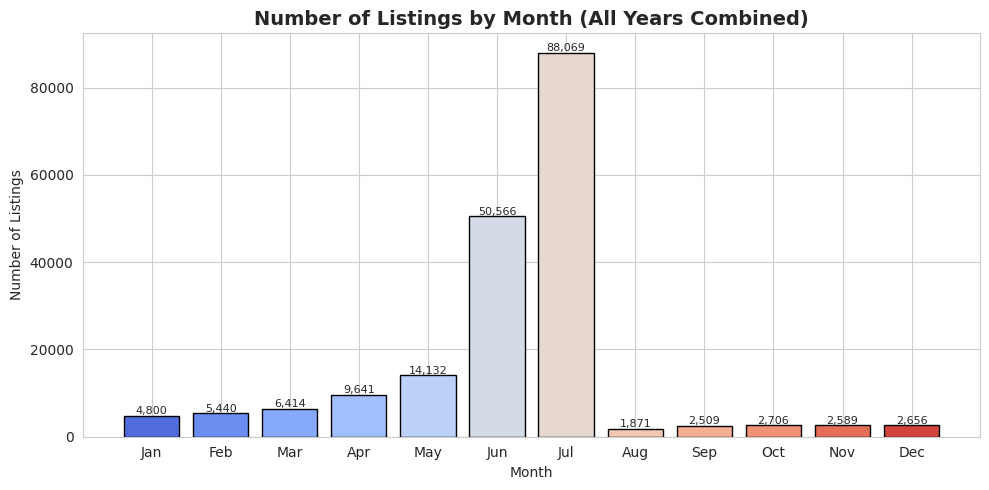

📊 Peak month for listings: Jul (88,069 listings)


In [ ]:
# ──────────────────────────────────────────────
# BQ5: Seasonal trends — listings by month
# ──────────────────────────────────────────────

monthly_counts = df.groupby('month').size().reset_index(name='count')
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(monthly_counts['month'], monthly_counts['count'],
              color=sns.color_palette('coolwarm', 12), edgecolor='black')
ax.set_title('Number of Listings by Month (All Years Combined)', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Number of Listings')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)

for bar, val in zip(bars, monthly_counts['count']):
    ax.text(bar.get_x() + bar.get_width()/2, val + 300, f'{val:,}',
            ha='center', fontsize=8)

plt.tight_layout()
plt.show()

peak_month = monthly_counts.loc[monthly_counts['count'].idxmax()]
print(f"📊 Peak month for listings: {month_names[int(peak_month['month'])-1]} ({int(peak_month['count']):,} listings)")

### BQ6: How do property sizes correlate with prices across cities and property types?

Correlation (area_in_marla vs price) by City:

  Lahore           r = 0.226
  Karachi          r = 0.100
  Islamabad        r = 0.097
  Faisalabad       r = 0.467
  Rawalpindi       r = 0.029

Correlation (area_in_marla vs price) by Property Type:

  House            r = 0.173
  Flat             r = 0.014
  Lower Portion    r = -0.004
  Penthouse        r = 0.081
  Upper Portion    r = -0.010
  Farm House       r = 0.582
  Room             r = 0.011


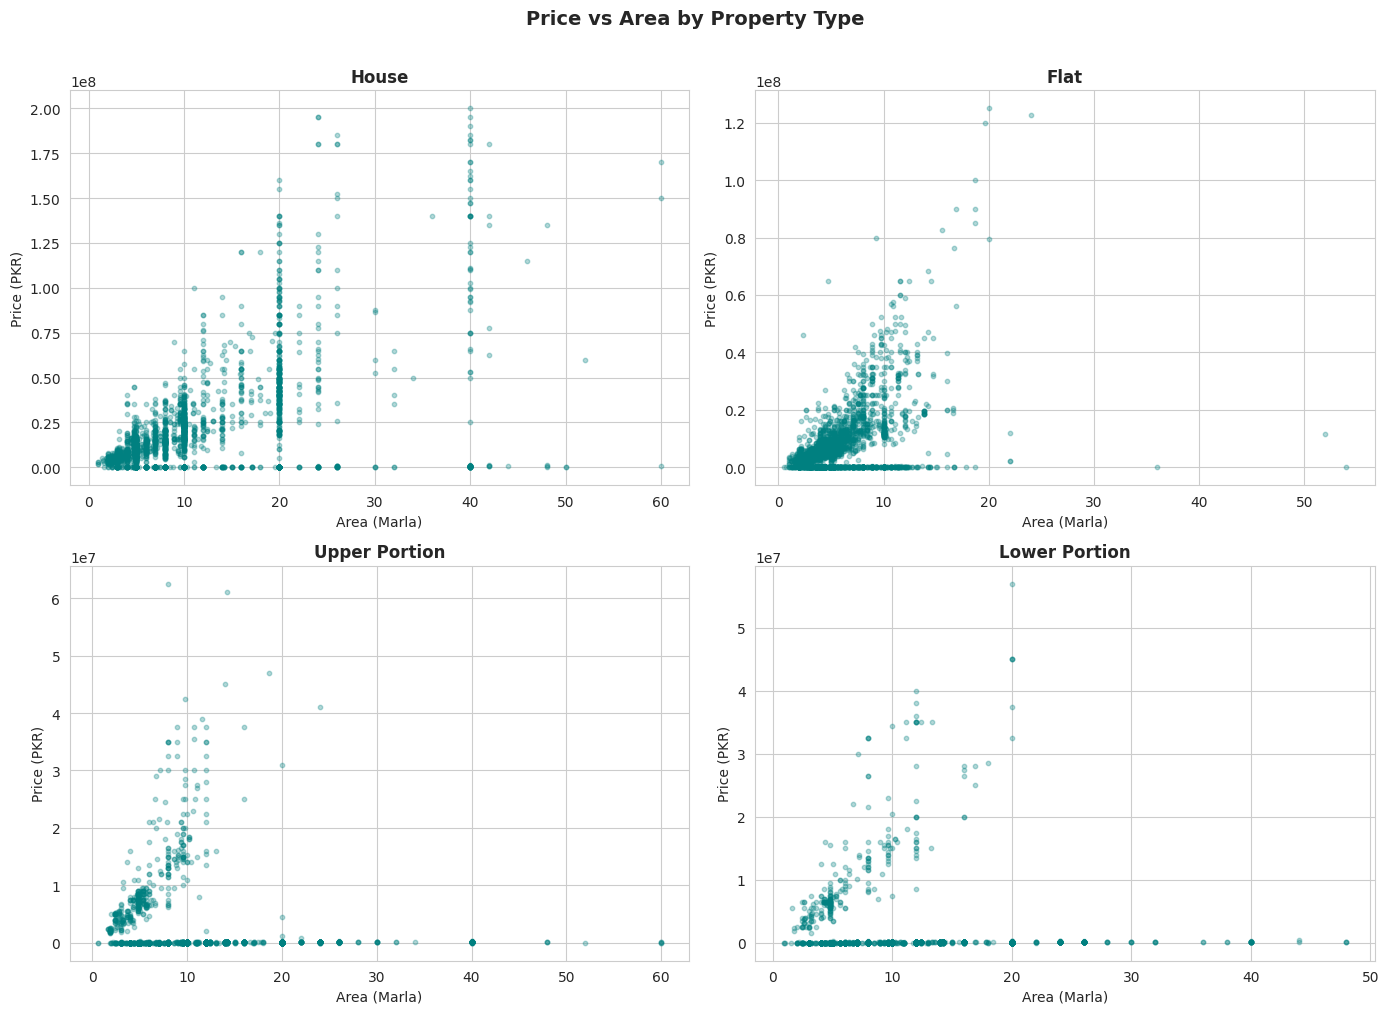

In [ ]:
# ──────────────────────────────────────────────
# BQ6: Size vs Price correlation by city and type
# ──────────────────────────────────────────────

# Compute correlation between area_in_marla and price for each city
print("Correlation (area_in_marla vs price) by City:\n")
for city in df['city'].unique():
    corr = df[df['city'] == city][['area_in_marla', 'price']].corr().iloc[0, 1]
    print(f"  {city:15s}  r = {corr:.3f}")

print("\nCorrelation (area_in_marla vs price) by Property Type:\n")
for ptype in df['property_type'].unique():
    corr = df[df['property_type'] == ptype][['area_in_marla', 'price']].corr().iloc[0, 1]
    print(f"  {ptype:15s}  r = {corr:.3f}")

# Scatter faceted by property type
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
top_types = ['House', 'Flat', 'Upper Portion', 'Lower Portion']

for ax, ptype in zip(axes.flatten(), top_types):
    ptype_data = df[(df['property_type'] == ptype) &
                    (df['area_in_marla'] <= 60) &
                    (df['price'] <= 200_000_000)]
    sample_pt = ptype_data.sample(n=min(3000, len(ptype_data)), random_state=42)
    ax.scatter(sample_pt['area_in_marla'], sample_pt['price'],
               alpha=0.3, s=10, color='teal')
    ax.set_title(f'{ptype}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Area (Marla)')
    ax.set_ylabel('Price (PKR)')

plt.suptitle('Price vs Area by Property Type', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### BQ7: Which property types are most prevalent in certain provinces and how does this affect prices?

Property Type Distribution by Province:

property_type      Farm House   Flat  House  Lower Portion  Penthouse  Room  \
province_name                                                                 
Islamabad Capital         253   7514  21280           4720         51   391   
Punjab                    398   5642  72376           4292         29   507   
Sindh                      74  27001  25259           2681        319   131   

property_type      Upper Portion  
province_name                     
Islamabad Capital           5986  
Punjab                      7470  
Sindh                       5019  


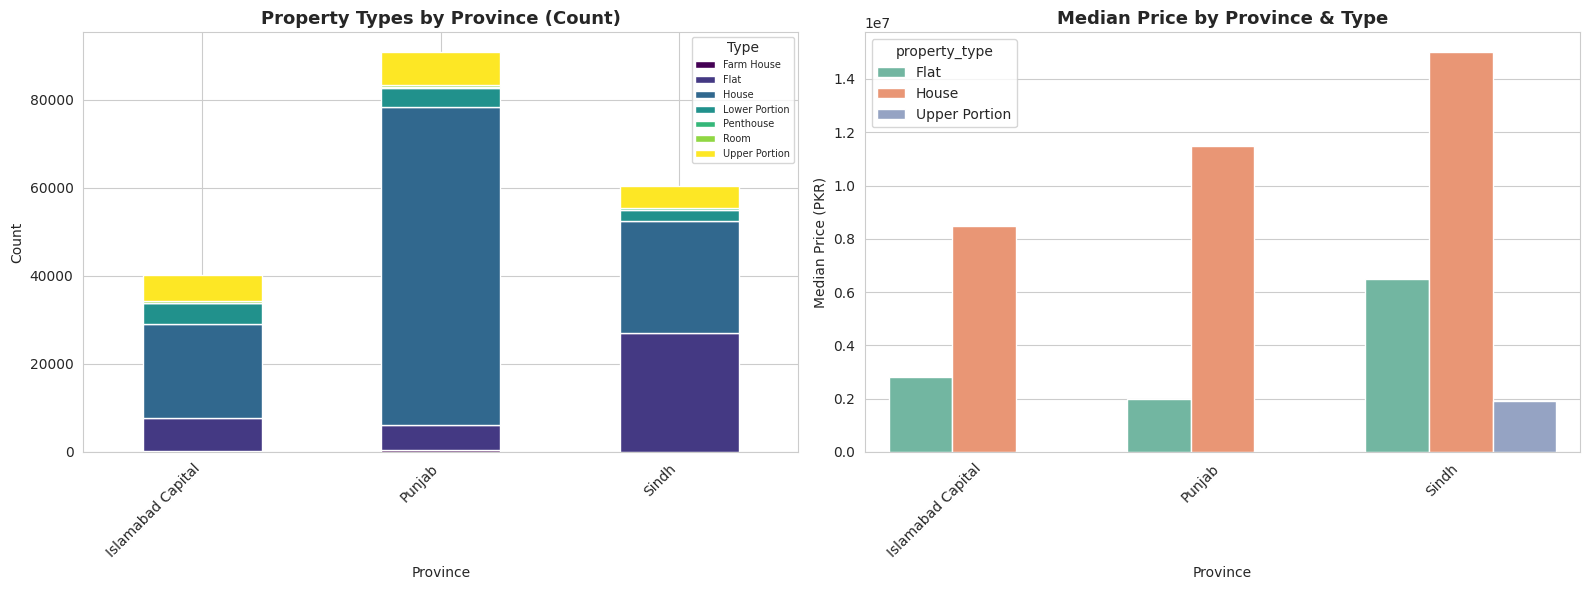

In [ ]:
# ──────────────────────────────────────────────
# BQ7: Property types by province + price impact
# ──────────────────────────────────────────────

# Cross-tabulation of province vs property type
province_type = pd.crosstab(df['province_name'], df['property_type'])
print("Property Type Distribution by Province:\n")
print(province_type)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Stacked bar of counts
province_type.plot(kind='bar', stacked=True, ax=axes[0],
                   colormap='viridis', edgecolor='white')
axes[0].set_title('Property Types by Province (Count)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Province')
axes[0].set_ylabel('Count')
axes[0].legend(fontsize=7, title='Type')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

# Right: Average price by province and property type
avg_by_prov_type = df.groupby(['province_name', 'property_type'])['price'].median().reset_index()
top_types_list = ['House', 'Flat', 'Upper Portion']
avg_filtered = avg_by_prov_type[avg_by_prov_type['property_type'].isin(top_types_list)]

sns.barplot(x='province_name', y='price', hue='property_type',
            data=avg_filtered, palette='Set2', ax=axes[1])
axes[1].set_title('Median Price by Province & Type', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Province')
axes[1].set_ylabel('Median Price (PKR)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

### BQ8: How does the number of bathrooms influence prices in different cities?

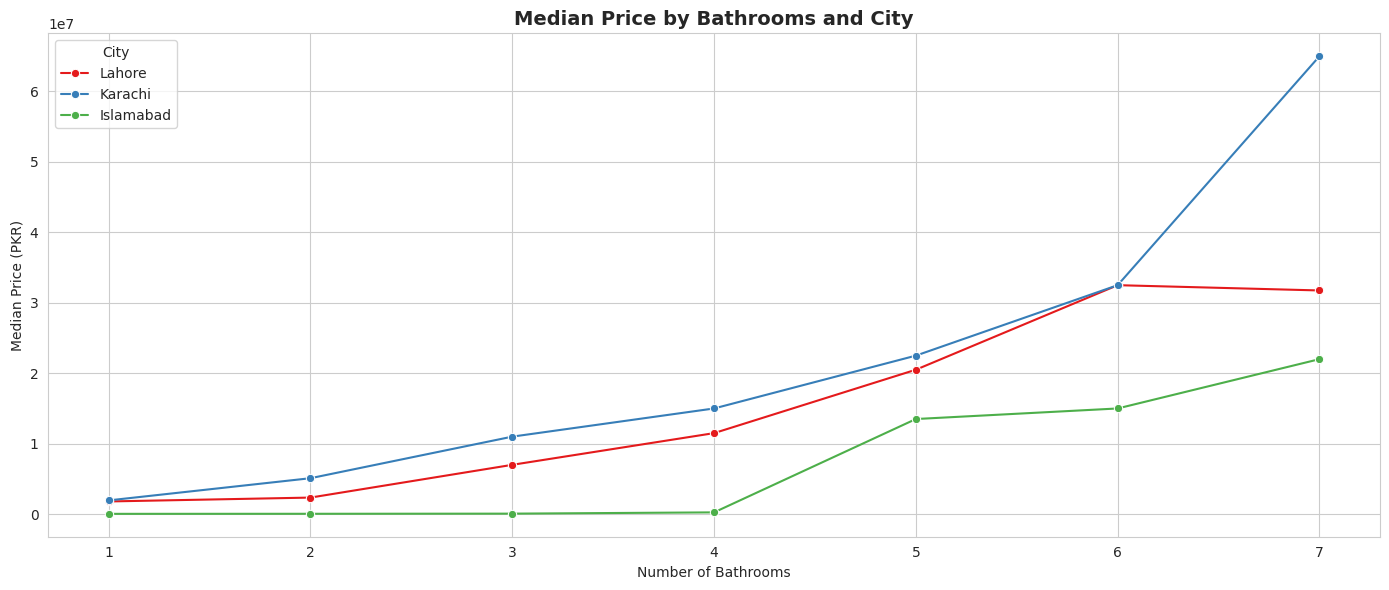

📊 Insight: In all three cities, prices rise with bathroom count.
   Islamabad shows the steepest increase — luxury properties there
   command a significant premium over Karachi and Lahore.


In [ ]:
# ──────────────────────────────────────────────
# BQ8: Bathrooms vs Price by City
# ──────────────────────────────────────────────

mask = (df['baths'] >= 1) & (df['baths'] <= 7) & (df['city'].isin(top3_cities))
bath_city = df[mask]

fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(x='baths', y='price', hue='city', data=bath_city,
             palette='Set1', marker='o', ci=None, estimator=np.median, ax=ax)
ax.set_title('Median Price by Bathrooms and City', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Bathrooms')
ax.set_ylabel('Median Price (PKR)')
ax.legend(title='City')

plt.tight_layout()
plt.show()

print("📊 Insight: In all three cities, prices rise with bathroom count.")
print("   Islamabad shows the steepest increase — luxury properties there")
print("   command a significant premium over Karachi and Lahore.")

### BQ9: Distribution of properties by purpose (Sale vs. Rent) across cities

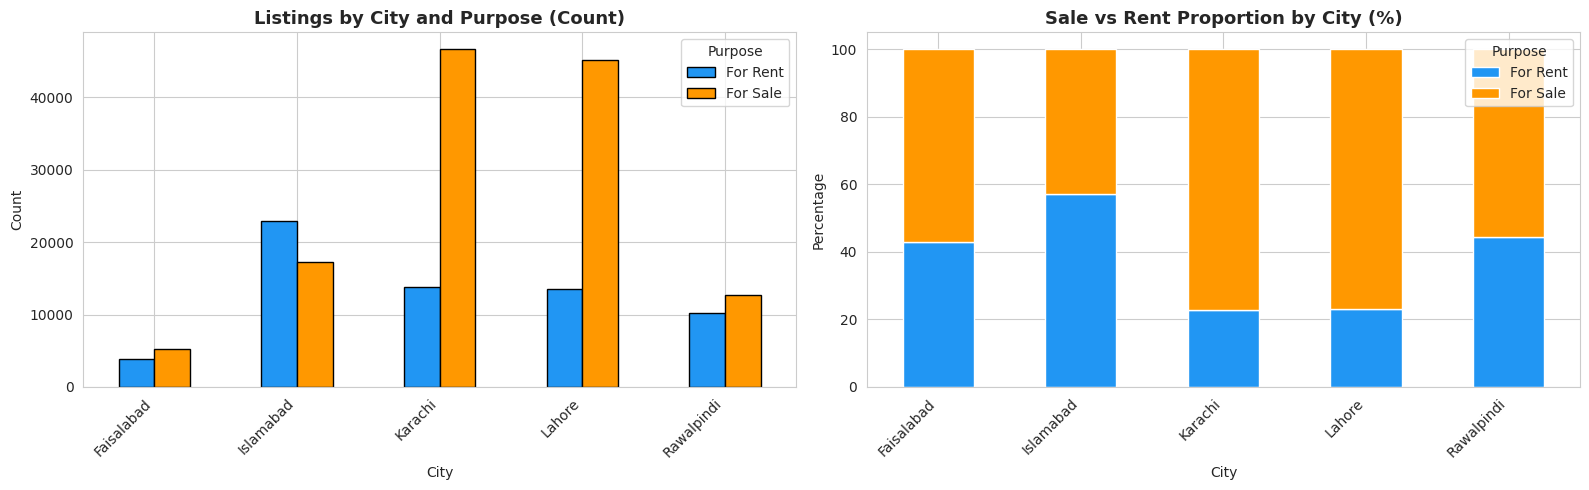


Sale vs Rent breakdown by city:

purpose     For Rent  For Sale
city                          
Faisalabad      42.8      57.2
Islamabad       57.2      42.8
Karachi         22.8      77.2
Lahore          23.0      77.0
Rawalpindi      44.4      55.6


In [ ]:
# ──────────────────────────────────────────────
# BQ9: For Sale vs For Rent distribution by city
# ──────────────────────────────────────────────

purpose_city = pd.crosstab(df['city'], df['purpose'])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: Absolute counts
purpose_city.plot(kind='bar', ax=axes[0], color=['#2196F3', '#FF9800'], edgecolor='black')
axes[0].set_title('Listings by City and Purpose (Count)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('City')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].legend(title='Purpose')

# Right: Percentage breakdown
purpose_pct = purpose_city.div(purpose_city.sum(axis=1), axis=0) * 100
purpose_pct.plot(kind='bar', stacked=True, ax=axes[1],
                 color=['#2196F3', '#FF9800'], edgecolor='white')
axes[1].set_title('Sale vs Rent Proportion by City (%)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('City')
axes[1].set_ylabel('Percentage')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].legend(title='Purpose')

plt.tight_layout()
plt.show()

print("\nSale vs Rent breakdown by city:\n")
print(purpose_pct.round(1).to_string())

### BQ10: Which agents are most active in high-value property markets?

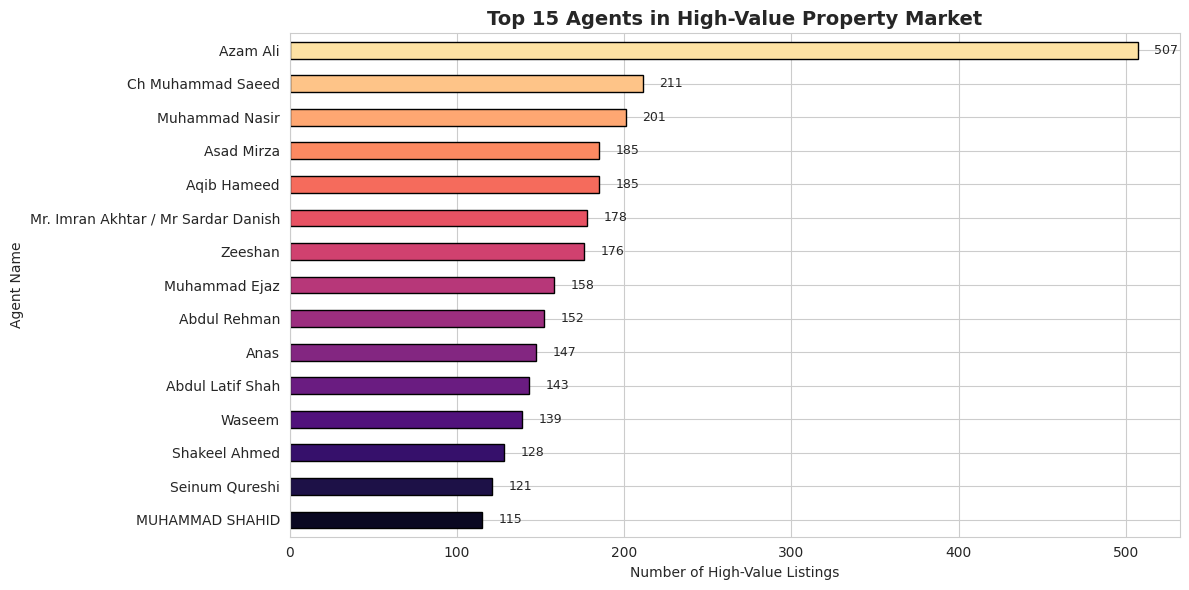


Most active agent in high-value market: 'Azam Ali' with 507 listings.


In [ ]:
# ──────────────────────────────────────────────
# BQ10: Most active agents in high-value markets
# ──────────────────────────────────────────────

# High-value = above 75th percentile
high_val = df[(df['price'] >= threshold) & (df['agent'] != 'Unknown')]

top_agents = high_val['agent'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(12, 6))
top_agents.sort_values().plot(kind='barh', color=sns.color_palette('magma', 15),
                               edgecolor='black', ax=ax)
ax.set_title('Top 15 Agents in High-Value Property Market', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of High-Value Listings')
ax.set_ylabel('Agent Name')

for i, val in enumerate(top_agents.sort_values().values):
    ax.text(val + 10, i, f'{val:,}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print(f"\nMost active agent in high-value market: '{top_agents.index[0]}' with {top_agents.values[0]:,} listings.")

---
## 📋 Insight Summary — Key Business Takeaways

### Market Overview
- The dataset contains **191,000+** property listings across **5 cities** in Pakistan.
- **Houses** dominate the market (~62% of all listings), followed by **Flats** (~21%).
- **Karachi** and **Lahore** lead in listing volume, while **Islamabad** commands premium prices.

### Pricing Insights
- Property prices are **highly right-skewed** — a small number of ultra-luxury properties pull the average way above the median.
- **Area (in Marla)** and **number of bathrooms** have the strongest positive correlation with price.
- For the same property size, **Islamabad** is consistently the most expensive city, followed by Lahore and then Karachi.

### Market Trends
- Listing volume has generally **increased** over the years, indicating a growing digital real estate market.
- **Houses** remain the most popular type across all cities and time periods.
- Certain months show higher listing activity, suggesting **seasonal patterns** in the market.

### Investment Recommendations
1. **For high returns:** Focus on Islamabad — it shows strong price appreciation and premium positioning.
2. **For volume plays:** Karachi and Lahore offer the most inventory and transaction potential.
3. **Agency opportunity:** A significant portion of listings lack agency representation (25% have "Unknown" agency), suggesting room for real estate agencies to grow.
4. **Property type focus:** Houses and Flats are the bread-and-butter of the market — niche types like Penthouses and Farm Houses are small segments.

---
*End of Analysis*